### **Tarea: Taller Resolucion de Problemas-Grupo A**

**Grupo asignado:**
- Gabriela Oyarzo
- Thomas Aguayo
- Victor Donoso
- Matias Cáceres

In [113]:
#1. Install packages
print('-----------------------------------------------------------------------')
print('Instalando paquetes...')

# completar agregando los paquetes necesarios...
import numpy as np
import matplotlib.pyplot as plt
import random
from mpl_toolkits.mplot3d import Axes3D
# ... import more

# #2. Link Google Drive
# from google.colab import drive
# drive.mount('/content/drive')

# # nombre de carpeta con las funciones
# project_folder = "GLHS-TRP/"
print('Paquetes correctamente cargados')
print('-----------------------------------------------------------------------')


-----------------------------------------------------------------------
Instalando paquetes...
Paquetes correctamente cargados
-----------------------------------------------------------------------


In [114]:
np.random.seed(27)
random.seed(27)

# parameters
input_dim = 2
nb_pts    = 30000       # para grid inicial
eps       = 0
# crear una malla con dimension (nb_pts,input_dim) random.
X_grid = np.random.uniform(low=-1,high=1, size=(nb_pts, input_dim))

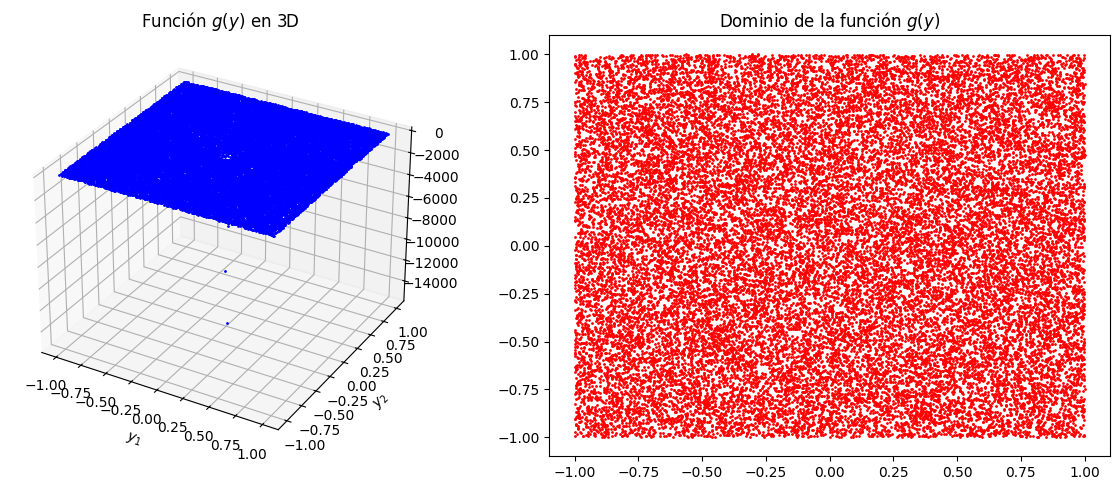

In [115]:
# definir funcion
def f_problem(X_grid):
# Extraemos y1 e y2 de la malla
    y1 = X_grid[:, 0]
    y2 = X_grid[:, 1]
    
    # Obtenemos la dimensión (d) de la malla
    d = X_grid.shape[1]
    
    # Calculamos la sumatoria
    sumatoria = np.sum(X_grid, axis=1)
    
    # Armamos la ecuación g(y) 
    y = ((10/7) - (1 / (y1**2 + y2**2))) * np.exp(-sumatoria / (2 * d))
    return y

# graficar funcion
f_val = f_problem(X_grid)

# 1. Create the base canvas figure
fig = plt.figure(figsize=(12, 5))

# 2. Add the second subplot with a 3D projection
ax1 = fig.add_subplot(1, 2, 1, projection='3d')  # 1 row, 2 columns, position 2
ax1.plot3D(X_grid[:,0], X_grid[:,1], f_val, '.', ms=2, color='blue')
ax1.set_title(r'Función $g(y)$ en 3D')
ax1.set_xlabel(r'$y_1$'), ax1.set_ylabel(r'$y_2$')

# 3. Add the first subplot as a standard 2D plot
ax2 = fig.add_subplot(1, 2, 2)  # 1 row, 2 columns, position 1
ax2.plot(X_grid[:,0],X_grid[:,1],'.', ms= 2,color='red')
ax2.set_title(r'Dominio de la función $g(y)$')
plt.tight_layout()
plt.show()


Using 113 basis functions
Grid size: (30000, 2)
number of points: 30000
Using 113 basis functions
measurement matrix A size: (30000, 113)


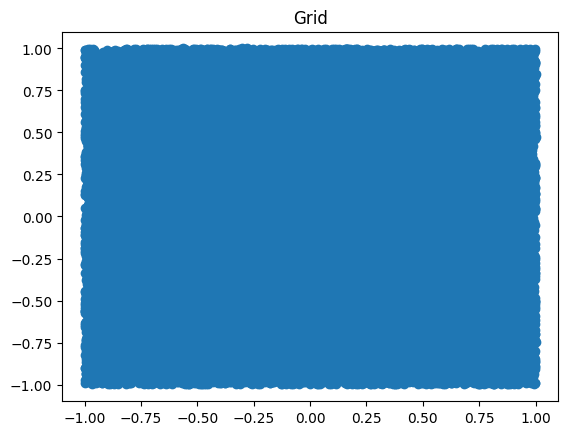

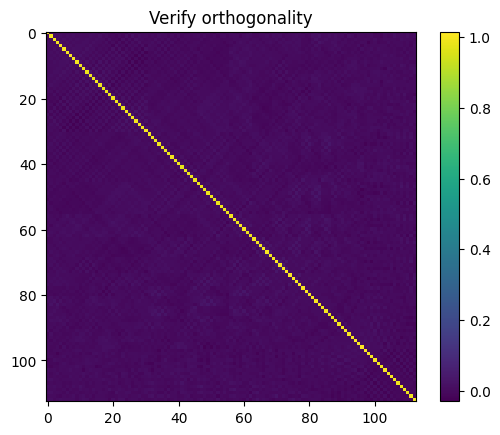

In [116]:
# Paso 1: Sampling strategy
"""
Construya la medida de probabilidad Cristoffel Sampling (CS)y Monte-Carlo (MC)
sobre el dominio actual.
"""
# import packages
from measurement_matrix import measurement_matrix
from m_samples_order import get_m_samples_from_order

# parameters for sampling
n_size    = 30
nb_basis  = get_m_samples_from_order(input_dim, n_size)
M_samples = np.round(nb_basis*np.log(nb_basis)).astype(int)

B_matrix = measurement_matrix(grid= X_grid, input_dim= input_dim, n_size= n_size)

def MC_sampling(M_samples):
    """
    Muestrea puntos usando la medida de monte carlo (o medida uniforme), selecciona
    los primeros M_samples porque la malla X_grid ya esta generada por la
    medida uniforme
    """
    M_samples = np.round(M_samples).astype(int)
    I_set_MC = np.arange(0,M_samples)
    return I_set_MC


def Christoffel_sampling(B_matrix, M_samples):
    """
    ----------------------------------------------------------------------------
    Inputs:

    B_matrix..... measurement matrix, inital basis evaluated on the error grid
    M_samples.... number of samples to draw  wrt Christoffel function inital basis

    Outpus:
    I_set........ indices of the M samples
    chris_func... Christoffel function evaluated in the M samples
    weights...... weights related to Christoffel Sampling
    ----------------------------------------------------------------------------
    """
    # parameters
    grid_size, nb_basis = B_matrix.shape
    error_grid          = np.arange(0,grid_size)
    M_samples           = np.round(M_samples).astype(int)
    I_set               = np.array([])

    # Construct sampling measure
    Q, R = np.linalg.qr(B_matrix)
    prob_measure = Q**2

    prob_measure = np.sum(prob_measure[:,0:nb_basis], axis=1)/nb_basis

    print(f"M samples: {M_samples}")
    print('size probability measure', prob_measure.shape, 'number of points:', grid_size)

    # Draw from sampling measure
    I_set = random.choices(error_grid, weights=prob_measure, k=M_samples)

    # reject repeated samples
    new_list = np.array([])
    dup_list = np.array([])

    for i in I_set:
        if i not in new_list:
            new_list = np.append(new_list, i)
        else:
            new_list = np.append(dup_list, i)

    # add remaining samples
    while len(new_list) <= M_samples:

        # draw samples
        I_add = random.choices(error_grid, weights=prob_measure, k=M_samples)

        for i in I_add:
            if i not in new_list:
                new_list = np.append(new_list, i)
            else:
                dup_list = np.append(dup_list, i)

    # delete extra m samples
    if len(new_list) > M_samples:
        I_set = new_list[0:M_samples]

    I_set = I_set.astype(int)

    # Compute weights
    Chris_func = prob_measure[I_set]
    weights    = np.sqrt(np.divide(1,Chris_func))

    return I_set, Chris_func, weights

In [117]:
# Paso 2: Muestrear puntos usando MC o CS

I_set_CS, Chris_func, weights = Christoffel_sampling(B_matrix, M_samples)
I_set_MC = MC_sampling(M_samples)

X_grid_MC = X_grid[I_set_MC,:]
X_grid_CS = X_grid[I_set_CS,:]

# Crear instancia donde se verifica la condicion Q(f(x)) =1
mask_MC = f_val[I_set_MC] >= 0
mask_CS = f_val[I_set_CS] >= 0

weights = weights[mask_CS]

# Solo dejar los puntos en el dominio de interes
I_set_MC = I_set_MC[mask_MC]
I_set_CS = I_set_CS[mask_CS]

M samples: 534
size probability measure (30000,) number of points: 30000


In [118]:
#------------------------------------------------------------------------------#
# Paso 3-parte 1:
# Construir la aproximacion usando Weighted-least squares con Christoffel
# Sampling
#------------------------------------------------------------------------------#

K = np.round(B_matrix.shape[0])
M = len(I_set_CS)

# evaluate ground truth funciton
g_truth_vals = f_val[I_set_CS]

# QR decomposition
Q_matrix, R_matrix = np.linalg.qr(B_matrix)

# retype weights and forms
weights= np.array(weights, dtype= np.float64).flatten()

# Weighted Least-squares
W_matrix = np.diag(weights)
A_matrix = np.matmul(W_matrix, Q_matrix[I_set_CS, :]) * np.sqrt(K/M)

b_vector = np.asarray(g_truth_vals, dtype=np.float64).flatten()
b_vector = np.matmul(W_matrix,b_vector)/np.sqrt(M)

coeffs = np.linalg.lstsq(A_matrix, b_vector, rcond=None)[0]
# evaluate surrogate on full grid
surrogate_vals_Z_l = np.sqrt(K) * np.matmul(Q_matrix, coeffs)
surrogate_vals_Z_M = surrogate_vals_Z_l[I_set_CS]

# Error en los M samples
error_M = np.linalg.norm(surrogate_vals_Z_M - g_truth_vals)

# Error en toda la malla
error_Z_l = np.linalg.norm(f_val - surrogate_vals_Z_l) / np.linalg.norm(f_val)


print(f'error on M-vals: {error_M}')
print(f'nb basis: {nb_basis}')
print(f'M_samples: {M_samples}')

error on M-vals: 0.021496241496333834
nb basis: 113
M_samples: 534


In [119]:
#------------------------------------------------------------------------------#
# Paso 3-parte 2:
# Construir la aproximacion usando least-squares con Monte Carlo Sampling
#------------------------------------------------------------------------------#

M_MC = len(I_set_MC) # Obtenemos el tamaño de la muestra de MC filtrada

# 1. Obtenemos los valores reales (ground truth) usando los índices de MC
g_truth_vals_MC = f_val[I_set_MC]

# 2. Armamos la matriz A (Sin la matriz W). Solo extraemos las filas correspondientes de Q_matrix y normalizamos.
A_matrix_MC = Q_matrix[I_set_MC, :] * np.sqrt(K/M_MC)

# 3. Formateamos el vector b y normalizamos (sin matriz W)
b_vector_MC = np.asarray(g_truth_vals_MC, dtype=np.float64).flatten()
b_vector_MC = b_vector_MC / np.sqrt(M_MC)

# 4. Resolvemos el sistema por mínimos cuadrados para obtener los coeficientes de MC
coeffs_MC = np.linalg.lstsq(A_matrix_MC, b_vector_MC, rcond=None)[0]

# 5. Evaluamos el modelo sustituto en toda la malla usando los coeficientes de MC
surrogate_vals_Z_l_MC = np.sqrt(K) * np.matmul(Q_matrix, coeffs_MC)

# Evaluamos en la muestra M
surrogate_vals_Z_M_MC = surrogate_vals_Z_l_MC[I_set_MC]

# 6. Errores de Monte Carlo
error_M_MC = np.linalg.norm(surrogate_vals_Z_M_MC - g_truth_vals_MC)
error_Z_l_MC = np.linalg.norm(f_val - surrogate_vals_Z_l_MC) / np.linalg.norm(f_val)

print(f'MC error on M-vals: {error_M_MC}')
print(f'MC error on Z-grid: {error_Z_l_MC}')

MC error on M-vals: 0.007582375993013327
MC error on Z-grid: 0.9989848932428027


In [120]:
# Paso 4: Calcular el dominio de interes Z_l

# Creamos las máscaras evaluando dónde los modelos sustitutos son >= 0
mask_Z_l_CS = surrogate_vals_Z_l >= 0
mask_Z_l_MC = surrogate_vals_Z_l_MC >= 0

# Obtenemos los puntos exactos de la malla que pertenecen al dominio Z_l
Z_l_CS = X_grid[mask_Z_l_CS]
Z_l_MC = X_grid[mask_Z_l_MC]

In [121]:
# Paso 5: Calcular la probabilidad de fallo
# Calculamos la probabilidad como (puntos en Z_l) / (puntos totales)
prob_fallo_CS = len(Z_l_CS) / nb_pts
prob_fallo_MC = len(Z_l_MC) / nb_pts

# Calcular la real para comparar:
prob_fallo_real = np.sum(f_val >= 0) / nb_pts

print(f"Prob. de fallo Real: {prob_fallo_real}")
print(f"Prob. de fallo CS: {prob_fallo_CS}")
print(f"Prob. de fallo MC: {prob_fallo_MC}")

Prob. de fallo Real: 0.4484666666666667
Prob. de fallo CS: 0.4498333333333333
Prob. de fallo MC: 0.4498
